# Object Detection with YOLO

*   Object Detection
*   YOLO for Object Detection
    * Dataset formats
    * Fine-tuning with a custom dataset
---

# YOLO for Object Detection

*   There are several open source implementations of each version of YOLO.
*   For this exercise, we will not be implementing the YOLO from scratch as it is a challenging model and requires many customized elements.
*   We will use the official Ultralytics YOLO11 implementation for this exercise.
*  The Ultralytics YOLO implementation is available as a Python package that can be installed via pip.

In [1]:
! pip install ultralytics

In [2]:
# check
import ultralytics
ultralytics.checks()

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Setup complete ✅ (12 CPUs, 53.0 GB RAM, 0.8/235.7 GB disk)


## YOLO model - first test

In [3]:
from ultralytics import YOLO

# Load a model
# model = YOLO('yolo11n.yaml')  # build a new model from scratch
model = YOLO('yolo11n.pt')  # load a pretrained model (recommended for training)
# Use the model
results = model('https://ultralytics.com/images/bus.jpg')  # predict on an image


Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
image 1/1 /content/bus.jpg: 640x480 4 persons, 1 bus, 9.9ms
Speed: 44.3ms preprocess, 9.9ms inference, 13.9ms postprocess per image at shape (1, 3, 640, 480)


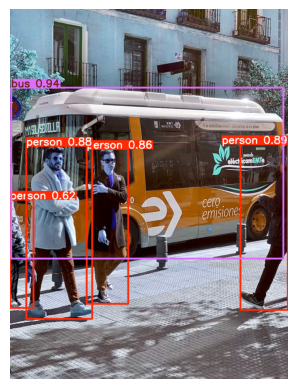

In [4]:
import matplotlib.pyplot as plt
plt.imshow(results[0].plot())
plt.axis('off')
plt.show()

In [5]:
# Understanding the Results object
print(type(results[0]))
print(dir(results[0]))
print(help(results[0]))

<class 'ultralytics.engine.results.Results'>
['__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattr__', '__getattribute__', '__getitem__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__len__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__static_attributes__', '__str__', '__subclasshook__', '__weakref__', '_apply', '_keys', 'boxes', 'colors', 'cpu', 'cuda', 'depth', 'keypoints', 'masks', 'merge_tiles', 'names', 'new', 'numpy', 'obb', 'orig_img', 'orig_shape', 'path', 'plot', 'probs', 'save', 'save_crop', 'save_dir', 'save_txt', 'semantic_mask', 'show', 'speed', 'summary', 'to', 'to_csv', 'to_df', 'to_json', 'update', 'verbose']
Help on Results in module ultralytics.engine.results object:

class Results(ultralytics.utils.SimpleClass, ultralytics.utils.DataExportMixin)
 |  Results(
 |      orig_img: 'np.nda

In [6]:
# Understanding the Boxes object
print(type(results[0].boxes))
print(dir(results[0].boxes))
print(help(results[0].boxes))

<class 'ultralytics.engine.results.Boxes'>
['__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattr__', '__getattribute__', '__getitem__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__len__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__static_attributes__', '__str__', '__subclasshook__', '__weakref__', '_convert', 'cls', 'conf', 'cpu', 'cuda', 'data', 'id', 'is_track', 'numpy', 'orig_shape', 'shape', 'to', 'xywh', 'xywhn', 'xyxy', 'xyxyn']
Help on Boxes in module ultralytics.engine.results object:

class Boxes(BaseTensor)
 |  Boxes(boxes: 'torch.Tensor | np.ndarray', orig_shape: 'tuple[int, int]') -> 'None'
 |
 |  A class for managing and manipulating detection boxes.
 |
 |  This class provides comprehensive functionality for handling detection boxes, including their coordinates,
 |  confidence scores, c

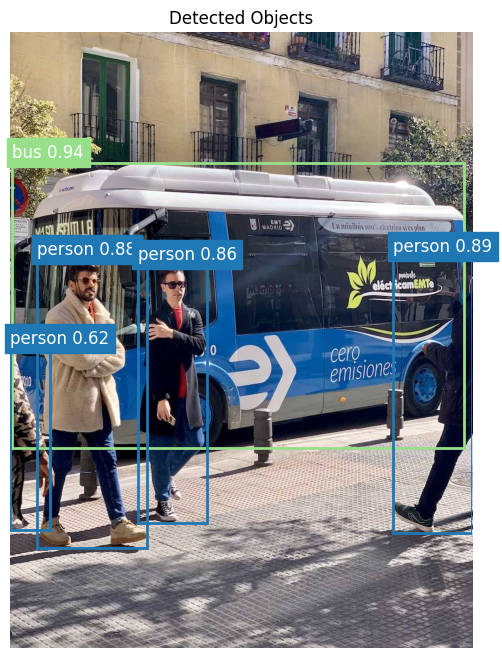

In [7]:
# Plotting the results in a more customizable way can be done using matplotlib by accessing
# the boxes and labels from the results object.
import cv2
import matplotlib

boxes = results[0].boxes
labels = results[0].names

fig, ax = plt.subplots(1, 1, figsize=(12, 8))
ax.imshow(cv2.cvtColor(results[0].orig_img, cv2.COLOR_BGR2RGB))

# define a color map for different classes
colors = matplotlib.colormaps.get_cmap('tab20')

# plot each box
for box in boxes:
    x1, y1, x2, y2 = box.xyxy[0].cpu()
    conf = box.conf[0].cpu()
    cls = int(box.cls[0])
    label = labels[cls]

    # create a rectangle patch
    rect = plt.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=2, edgecolor=colors(cls), facecolor='none')
    ax.add_patch(rect)
    ax.text(x1, y1 - 10, f'{label} {conf:.2f}', color='white', fontsize=12, backgroundcolor=colors(cls))

plt.axis('off')
plt.title('Detected Objects')
plt.show()


# YOLO customization and training with custom data
*   In this exercise, we will fine-tune a pre-trained YOLO model on a custom dataset.
*   We will prepare the dataset in the required format.
*   We will customize the YOLO model configuration to fit our dataset.

We will use RoboFlow's blood cell detection dataset for this exercise:
https://universe.roboflow.com/tumor-4iauk/blood-cell-st9na

This dataset contains microscopic images of different cells:

* PC - Platelets / Thrombocytes - Small, non-nucleated blood cells essential for hemostasis (stopping bleeding). They clump together to form a plug at the site of a damaged blood vessel wall.
* RBC - Red Blood Cells / Erythrocytes - The most abundant blood cells, responsible for transporting oxygen from the lungs to the body's tissues and carrying carbon dioxide back to the lungs.
* WBC - White Blood Cells / Leukocytes - These cells are the core components of the immune system, defending the body against infections, foreign invaders (bacteria, viruses), and abnormal cells.

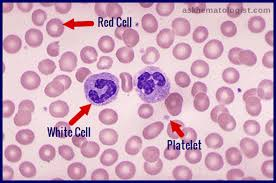

Reference:
```
@misc{
    blood-cell-st9na_dataset,
    title = { blood cell Dataset },
    type = { Open Source Dataset },
    author = { tumor },
    howpublished = { \url{ https://universe.roboflow.com/tumor-4iauk/blood-cell-st9na } },
    url = { https://universe.roboflow.com/tumor-4iauk/blood-cell-st9na },
    journal = { Roboflow Universe },
    publisher = { Roboflow },
    year = { 2024 },
    month = { sep },
    note = { visited on 2025-11-17 },
    }

```



### Understanding the COCO and YOLO dataset formats

In [ ]:
# COCO format annotation example
dummy_coco_annotation = {
    "images": [
        {
            "id": 1,
            "width": 640,
            "height": 480,
            "file_name": "image1.jpg"
        },
        {
            "id": 2,
            "width": 800,
            "height": 600,
            "file_name": "image2.jpg"
        }
    ],
    "annotations": [
        {
            "id": 1,
            "image_id": 1,
            "category_id": 1,
            "bbox": [100, 150, 200, 300],  # [x, y, width, height]
            "area": 60000,
            "iscrowd": 0
        },
        {
            "id": 2,
            "image_id": 2,
            "category_id": 1,
            "bbox": [50, 75, 100, 150],
            "area": 15000,
            "iscrowd": 0
        },
        {
            "id": 3,
            "image_id": 2,
            "category_id": 2,
            "bbox": [300, 400, 120, 180],
            "area": 5000,
            "iscrowd": 0
        }
    ],
    "categories": [
        {
            "id": 1,
            "name": "person"
        },
        {
            "id": 2,
            "name": "dog"
        }
    ]
}

YOLO expects the data to be in a different format:

```
├── data.yaml
├── test
│   ├── images
│   │   ├── 018239dc-02bb-5c9c-be33-0737ee53d592_jpg.rf.53258de6e413c4f33f824fb33c5883a3.jpg
│   └── labels
│       ├── 018239dc-02bb-5c9c-be33-0737ee53d592_jpg.rf.53258de6e413c4f33f824fb33c5883a3.txt
├── train
│   ├── images
│   └── labels
└── valid
    ├── images
    └── labels
```

data.yaml:
```
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 3
names: ['PC', 'RBC', 'WBC']
```


### Prepare data

Load the `_annotations.coco.json` from `blood_cell.v1i.coco/train` folder.

Our current data structure is following:

```
├── test
│   ├── f92c6c01-26a6-571d-81b1-0e2e2d50a1a9_jpg.rf.857f296efb37cffab62976e16fcedc17.jpg
│   ├── another_test_image.jpg
├── train
│   ├── f92c6c01-26a6-571d-81b1-0e2e2d50a1a9_jpg.rf.857f296efb37cffab62976e16fcedc17.jpg
│   ├── another_train_image.jpg
└── valid
│   ├── f92c6c01-26a6-571d-81b1-0e2e2d50a1a9_jpg.rf.857f296efb37cffab62976e16fcedc17.jpg
│   ├── another_val_image.jpg
```

We need to convert them to YOLO folder structure and create the missing label txt files and `data.yaml` file.

***Note that you can already download the same data in YOLO format from roboflow, but in most of the real-world scenarios, you will have to do this manually. This COCO to YOLO conversion is a simple exercise to get to understand it and be prepared in the future.***

Create a function `coco_to_yolo(input_folder, output_folder)` that does the following:
* Creates `images` and `labels` folder in `output_folder`.
* Copies all the image files (`.jpg, .png` etc) to the newly created `images` folder.
* Reads `input_folder/_annotations.coco.json` into a dictionary.
* Extracts annotations and reformats them into a YOLO format and write into a `{image_name}.txt` file inside the newly created `labels` folder. The content of `{image_name}.txt` should be as follows:
    ```
      class_id x_center y_center width height
      class_id x_center y_center width height
      ...
    ```
    where each line is one bounding box belonging to `{image_name}.jpg`.

Call the function three times:
* `coco_to_yolo(os.path.join(root_path, 'blood_cell.v1i.coco/train'), os.path.join(root_path, 'blood_cell.v1i.yolov11/train'))`
* `coco_to_yolo(os.path.join(root_path, 'blood_cell.v1i.coco/valid'), os.path.join(root_path, 'blood_cell.v1i.yolov11/valid'))`
* `coco_to_yolo(os.path.join(root_path, 'blood_cell.v1i.coco/test'), os.path.join(root_path, 'blood_cell.v1i.yolov11/test'))`


In [9]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
# unzip the COCO dataset (uploaded as a single zip) into Drive, only once
import os
zip_path = "/content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.coco.zip"
coco_dir = "/content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.coco"
if not os.path.exists(os.path.join(coco_dir, "train", "_annotations.coco.json")):
    !unzip -q -o "{zip_path}" -d "{coco_dir}"
print(sorted(os.listdir(coco_dir)))

['README.dataset.txt', 'README.roboflow.txt', 'test', 'train', 'valid']


In [13]:
import os
import json
import shutil

def coco_to_yolo(input_folder, output_folder):
    images_dir = os.path.join(output_folder, "images")
    labels_dir = os.path.join(output_folder, "labels")

    os.makedirs(images_dir, exist_ok=True)
    os.makedirs(labels_dir, exist_ok=True)

    # move images
    exts = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
    for f in os.listdir(input_folder):
        src = os.path.join(input_folder, f)
        if os.path.isfile(src):
            ext = os.path.splitext(f)[1].lower()
            if ext in exts:
                shutil.copy(src, os.path.join(images_dir, f))

    # load COCO
    coco_path = os.path.join(input_folder, "_annotations.coco.json")
    with open(coco_path, "r") as f:
        coco = json.load(f)

    images = {img["id"]: img for img in coco["images"]}
    anns_by_img = {}
    for ann in coco["annotations"]:
        iid = ann["image_id"]
        anns_by_img.setdefault(iid, []).append(ann)

    # generate YOLO txt
    for img_id, img_info in images.items():
        file_name = img_info["file_name"]
        width = img_info["width"]
        height = img_info["height"]

        stem = os.path.splitext(os.path.basename(file_name))[0]
        yolo_path = os.path.join(labels_dir, stem + ".txt")

        lines = []
        for ann in anns_by_img.get(img_id, []):
            cid = ann["category_id"] - 1  # coco starts with 1, yolo needs [0, N-1]
            x, y, w, h = ann["bbox"]
            xc = (x + w / 2) / width
            yc = (y + h / 2) / height
            wn = w / width
            hn = h / height
            lines.append(f"{cid} {xc} {yc} {wn} {hn}")

        with open(yolo_path, "w") as f:
            f.write("\n".join(lines))

# change root path as needed
root_path = "/content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO"
coco_root_path = f"{root_path}/blood_cell.v1i.coco"
yolo_root_path = f"{root_path}/blood_cell.v1i.yolov11"
coco_to_yolo(os.path.join(coco_root_path, 'train'), os.path.join(yolo_root_path, 'train'))
coco_to_yolo(os.path.join(coco_root_path, 'valid'), os.path.join(yolo_root_path, 'valid'))
coco_to_yolo(os.path.join(coco_root_path, 'test'), os.path.join(yolo_root_path, 'test'))

Create the `data.yaml` with the new data structure

In [14]:
# data.yaml
import os
import shutil

root_path = "/content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11"

# create data.yaml
data_yaml = f"""
train: {os.path.join(root_path, 'train/images')}
val: {os.path.join(root_path, 'valid/images')}
test: {os.path.join(root_path, 'test/images')}

nc: 3
names: ['PC', 'RBC', 'WBC']
"""

with open(os.path.join(root_path, 'data.yaml'), 'w') as f:
    f.write(data_yaml)

We still have the coco json files, let's load it and do some simple exploration

Steps:
* Load `_annotations.coco.json` from `train` and print/plot
    * number of images
    * number of annotations
    * class distribution (number of images per class)
* Load N=5 images and plot them with bounding boxes

Number of images: 3027
Number of annotations: 55881


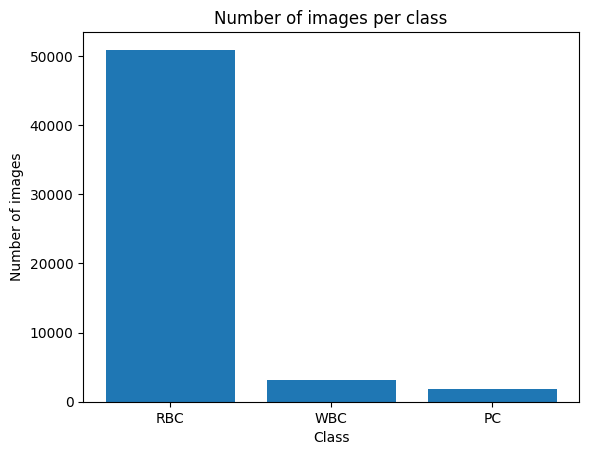

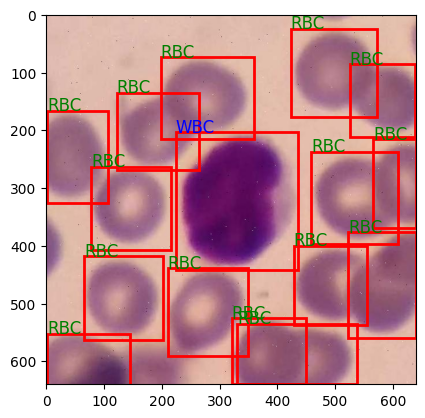

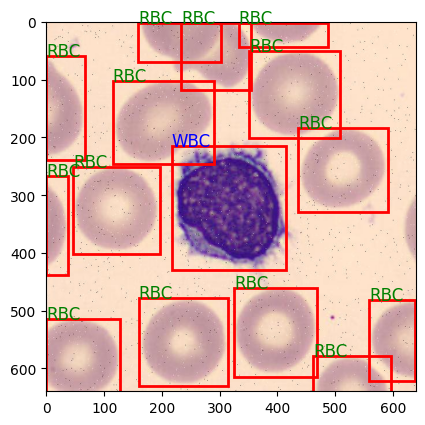

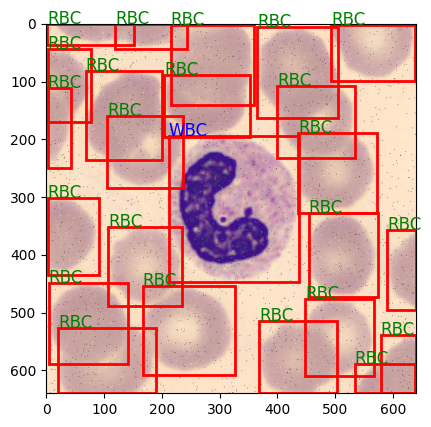

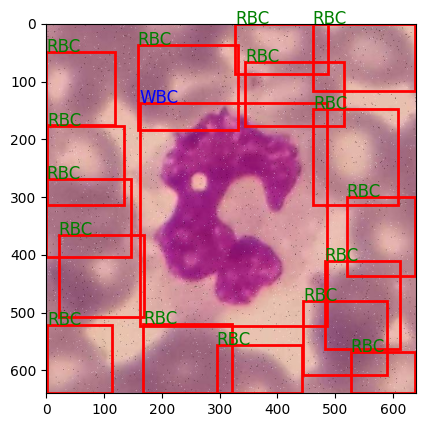

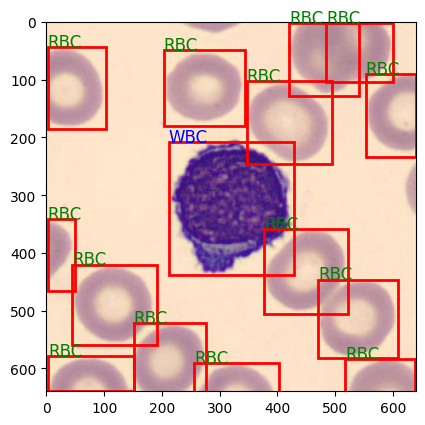

In [15]:
from skimage import io
import matplotlib.pyplot as plt

coco = json.load(open(os.path.join(coco_root_path, 'train/_annotations.coco.json')))
print(f'Number of images: {len(coco["images"])}')
print(f'Number of annotations: {len(coco["annotations"])}')
# count the number of images per class
class_counts = {}
for annotation in coco["annotations"]:
    category_id = annotation["category_id"]
    category_name = coco["categories"][category_id]["name"]
    if category_name not in class_counts:
        class_counts[category_name] = 0
    class_counts[category_name] += 1

plt.bar(class_counts.keys(), class_counts.values())
plt.xlabel('Class')
plt.ylabel('Number of images')
plt.title('Number of images per class')
plt.show()

# load 5 images and plot them with bounding boxes
for i in range(5):
    image_id = coco["images"][i]["id"]
    image_path = os.path.join(root_path, 'train/images', coco["images"][i]["file_name"])
    image = io.imread(image_path)
    fig, ax = plt.subplots(1)
    ax.imshow(image)
    for annotation in coco["annotations"]:
        if annotation["image_id"] == image_id:
            x, y, w, h = annotation["bbox"]
            rect = plt.Rectangle((x, y), w, h, fill=False, edgecolor='red', linewidth=2)
            ax.add_patch(rect)
            if annotation["category_id"] == 1:
                color = 'red'
            elif annotation["category_id"] == 2:
                color = 'green'
            else:
                color = 'blue'
            ax.text(x, y, coco["categories"][annotation["category_id"]]["name"], color=color, fontsize=12)
    plt.show()

Do the same with the new YOLO version

Steps:
* Load all image-annotation pairs from `train` and print/plot
    * number of images
    * number of annotations
    * class distribution (number of images per class)
* Load N=5 images and plot them with bounding boxes

Number of images: 3027
Number of annotation files: 3027
Number of annotations: 55881


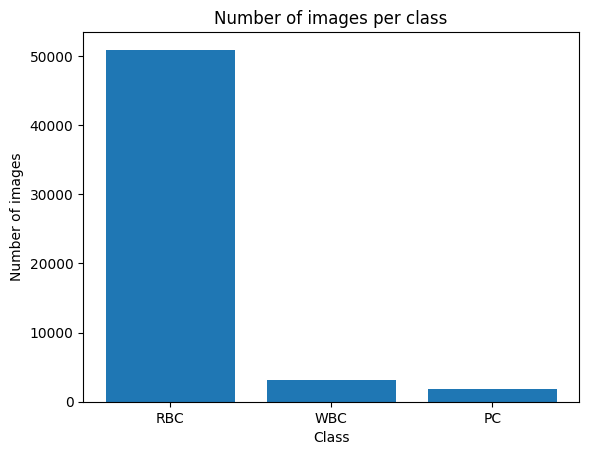

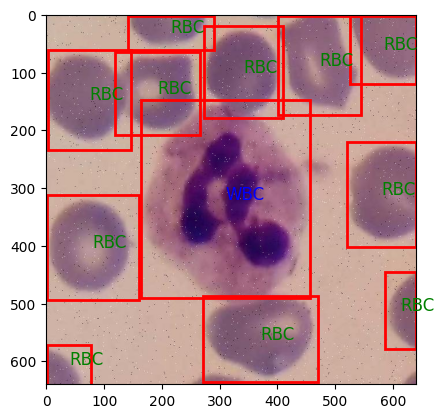

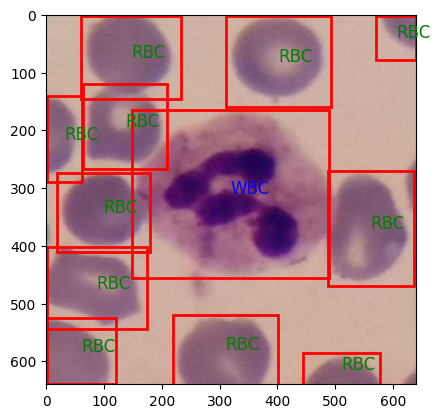

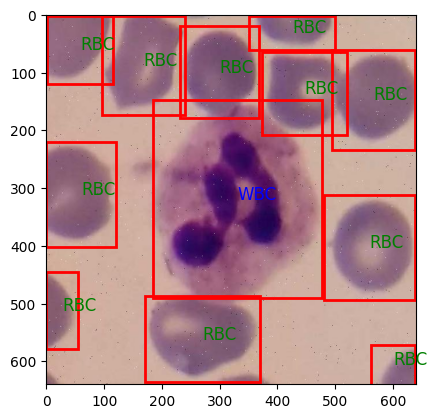

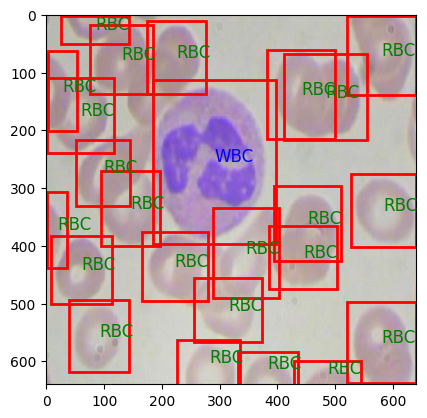

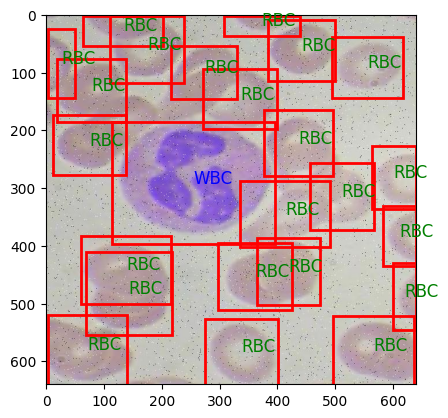

In [16]:
root_path = "/content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11"

# load all image-annotation pairs from train
image_paths = []
label_paths = []
for image_path in os.listdir(os.path.join(root_path, 'train/images')):
    image_paths.append(os.path.join(root_path, 'train/images', image_path))
    label_paths.append(os.path.join(root_path, 'train/labels', os.path.splitext(image_path)[0] + '.txt'))

print(f'Number of images: {len(image_paths)}')
print(f'Number of annotation files: {len(label_paths)}')
number_of_annotations = 0
class_counts = {}
for label_path in label_paths:
    with open(label_path, 'r') as f:
        for line in f.readlines():
            class_id = int(line.split()[0])
            if class_id not in class_counts:
                class_counts[class_id] = 0
            class_counts[class_id] += 1
            number_of_annotations += 1

print(f'Number of annotations: {number_of_annotations}')

class_names = {0: 'PC', 1: 'RBC', 2: 'WBC'}
# map class_counts.keys() to class_names
class_counts = {class_names[k]: v for k, v in class_counts.items()}
plt.bar(class_counts.keys(), class_counts.values())
plt.xlabel('Class')
plt.ylabel('Number of images')
plt.title('Number of images per class')
plt.show()

# plot 5 images with bounding boxes
for i in range(5):
    image_path = image_paths[i]
    label_path = label_paths[i]
    image = io.imread(image_path)
    fig, ax = plt.subplots(1)
    ax.imshow(image)
    with open(label_path, 'r') as f:
        for line in f.readlines():
            class_id, x, y, w, h = [float(x) for x in line.split()]
            x, y, w, h = x*image.shape[1], y*image.shape[0], w*image.shape[1], h*image.shape[0]
            rect = plt.Rectangle((x-w/2, y-h/2), w, h, fill=False, edgecolor='red', linewidth=2)
            ax.add_patch(rect)
            if class_id == 0:
                color = 'red'
            elif class_id == 1:
                color = 'green'
            else:
                color = 'blue'
            ax.text(x, y, class_names[int(class_id)], color=color, fontsize=12)
    plt.show()


# Customize YOLO ("yolo11n") model

In [17]:
from ultralytics import YOLO
import torch

model = YOLO("yolo11n.yaml")  # training from scratch

### Model training (from scratch)

In [18]:
# change root path as needed
root_path = "/content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11"

# https://docs.ultralytics.com/modes/train/#train-settings
model.train(
    data=f"{root_path}/data.yaml",
    name="from_scratch_50e_v1",
    epochs=50,
    batch=16,
    classes=[0, 1, 2],
    plots=True
)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=[0, 1, 2], close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.yaml, momentum=0.937, mosaic=1.0, multi_scale=0

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7fe694e81e10>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

In [19]:
# fine-tuning from COCO-pretrained weights, to compare with the from-scratch model
model_ft = YOLO("yolo11n.pt")
model_ft.train(data=f"{root_path}/data.yaml", name="finetune_50e_v1", epochs=50, batch=16, plots=True)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, nam

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7fe667bb1940>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

In [20]:
# show the training logs
runs_dir = "/content/runs"
# copy runs_dir logs to root_dir not to lose them after restart
!cp -r "/content/runs" "/content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO"

# Model Evaluation

In [21]:
from ultralytics import YOLO
import torch

# run_path = "/content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO"
run_path = "runs/detect/from_scratch_50e_v1"
model = YOLO(f"{run_path}/weights/best.pt")

#### Qualitative evaluation


/content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11/test/images/01e4af27-0d62-557e-b967-cd665b590d45_jpg.rf.a29b17fedb7f142ab8a107cd6d4f0bbd.jpg
/content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11/test/labels/01e4af27-0d62-557e-b967-cd665b590d45_jpg.rf.a29b17fedb7f142ab8a107cd6d4f0bbd.txt

image 1/1 /content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11/test/images/01e4af27-0d62-557e-b967-cd665b590d45_jpg.rf.a29b17fedb7f142ab8a107cd6d4f0bbd.jpg: 640x640 28 RBCs, 1 WBC, 9.4ms
Speed: 1.0ms preprocess, 9.4ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)
Prediction time: 0.14059185981750488 seconds


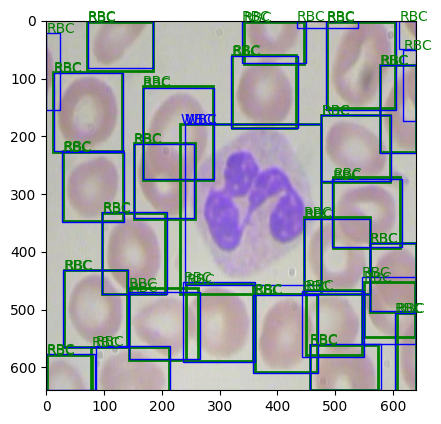

/content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11/test/images/02db46d5-f0f3-511c-b2cc-e907946e88e2_jpg.rf.5ebfbef49efe96859b237d59acd2a0df.jpg
/content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11/test/labels/02db46d5-f0f3-511c-b2cc-e907946e88e2_jpg.rf.5ebfbef49efe96859b237d59acd2a0df.txt

image 1/1 /content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11/test/images/02db46d5-f0f3-511c-b2cc-e907946e88e2_jpg.rf.5ebfbef49efe96859b237d59acd2a0df.jpg: 640x640 25 RBCs, 1 WBC, 10.8ms
Speed: 1.0ms preprocess, 10.8ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)
Prediction time: 0.02021622657775879 seconds


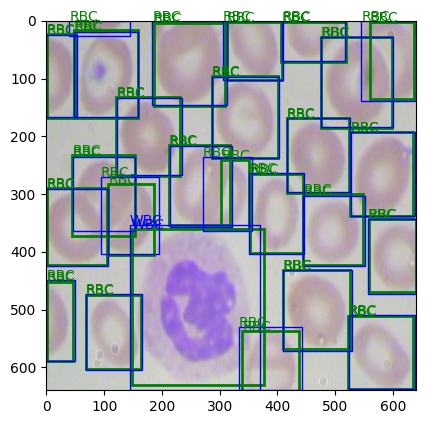

/content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11/test/images/035e0876-5358-5118-a956-116f8af710e4_jpg.rf.c6270d89a7f0ec150cfac4376bfa575d.jpg
/content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11/test/labels/035e0876-5358-5118-a956-116f8af710e4_jpg.rf.c6270d89a7f0ec150cfac4376bfa575d.txt

image 1/1 /content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11/test/images/035e0876-5358-5118-a956-116f8af710e4_jpg.rf.c6270d89a7f0ec150cfac4376bfa575d.jpg: 640x640 33 RBCs, 1 WBC, 10.8ms
Speed: 1.4ms preprocess, 10.8ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)
Prediction time: 0.020940303802490234 seconds


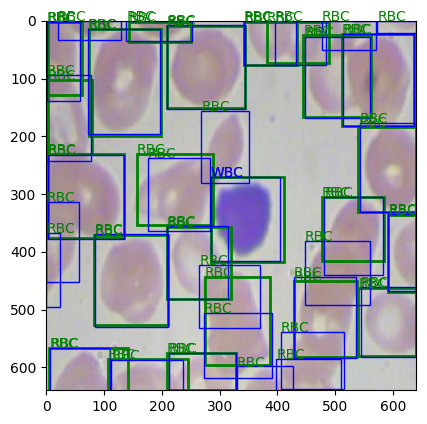

/content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11/test/images/0434941c-bce6-5060-b800-748937b7ea97_jpg.rf.b639ef3b6d52f6105852a31ca5607524.jpg
/content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11/test/labels/0434941c-bce6-5060-b800-748937b7ea97_jpg.rf.b639ef3b6d52f6105852a31ca5607524.txt

image 1/1 /content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11/test/images/0434941c-bce6-5060-b800-748937b7ea97_jpg.rf.b639ef3b6d52f6105852a31ca5607524.jpg: 640x640 22 RBCs, 1 WBC, 10.2ms
Speed: 1.0ms preprocess, 10.2ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)
Prediction time: 0.01909947395324707 seconds


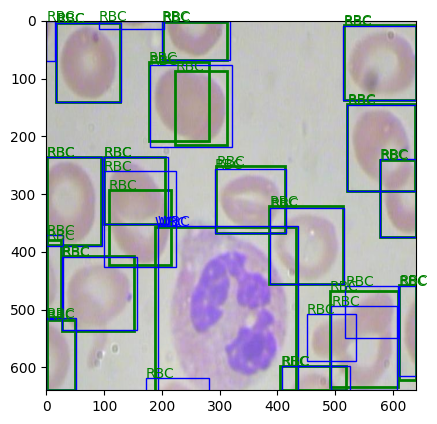

/content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11/test/images/04456893-a20e-59df-b157-42f4ddcb78f8_jpg.rf.9280212f4e7b01cb220a32cec857c7ed.jpg
/content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11/test/labels/04456893-a20e-59df-b157-42f4ddcb78f8_jpg.rf.9280212f4e7b01cb220a32cec857c7ed.txt

image 1/1 /content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11/test/images/04456893-a20e-59df-b157-42f4ddcb78f8_jpg.rf.9280212f4e7b01cb220a32cec857c7ed.jpg: 640x640 1 PC, 32 RBCs, 1 WBC, 10.1ms
Speed: 0.9ms preprocess, 10.1ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)
Prediction time: 0.01870274543762207 seconds


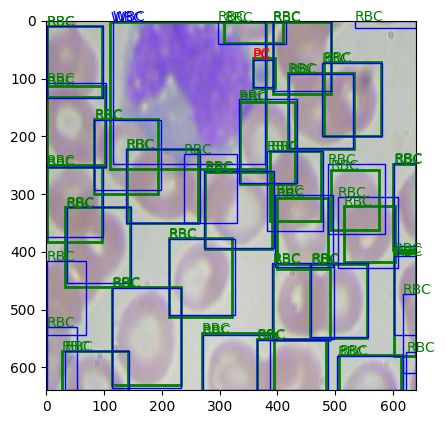

In [22]:
import os
from skimage import io
import matplotlib.pyplot as plt
import time

root_path = "/content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11"

test_images = os.listdir(f"{root_path}/test/images")
test_labels = os.listdir(f"{root_path}/test/labels")

categories = {
    0: "PC",
    1: "RBC",
    2: "WBC"
}

for i in range(5):
    image_path = os.path.join(f"{root_path}/test/images", test_images[i])
    label_path = os.path.splitext(image_path.replace("images", "labels"))[0] + ".txt"
    print(image_path)
    print(label_path)

    # load image and labels
    image = io.imread(image_path)
    with open(label_path, "r") as f:
        labels = f.readlines()

    start_time = time.time()
    with torch.no_grad():
        predict = model.predict(image_path)
    end_time = time.time()
    print(f"Prediction time: {end_time - start_time} seconds")
    # plot predictions and ground truth boxes
    fig, ax = plt.subplots(1)
    ax.imshow(image)
    for label in labels:
        label = label.split()
        x, y, w, h = [float(l) for l in label[1:]]
        # these are in yolo format so it needs processing before plotting
        x, y, w, h = x*image.shape[1], y*image.shape[0], w*image.shape[1], h*image.shape[0]
        rect = plt.Rectangle((x-w/2, y-h/2), w, h, fill=False, edgecolor='green', linewidth=2)
        ax.add_patch(rect)
        if int(label[0]) == 0:
            color = 'red'
        elif int(label[0]) == 1:
            color = 'green'
        else:
            color = 'blue'
        ax.text(x-w/2, y-h/2, categories[int(label[0])], color=color, fontsize=10)

    for box in predict[0].boxes:
        x, y, w, h = box.xywh[0].tolist()
        rect = plt.Rectangle((x-w/2, y-h/2), w, h, fill=False, edgecolor='blue', linewidth=1)
        ax.add_patch(rect)
        if box.cls[0].item() == 0:
            color = 'red'
        elif box.cls[0].item() == 1:
            color = 'green'
        else:
            color = 'blue'
        ax.text(x-w/2, y-h/2, categories[int(box.cls[0].item())], color=color, fontsize=10)
    plt.show()


### Quantitiatve evaluation

* Plot Precision-Recall Curve
* Plot False-Positives-Per-Image Curve
* Print a table with mAP@0.5, mAP@0.5-0.9

We can use the built-in evaluation methods from the YOLO library, which is shown below. But we should also learn to implement these metrics from scratch, so we will do that as well.

In [23]:
results = model.val(data=f"{root_path}/data.yaml", split="test")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO11n summary (fused): 100 layers, 2,582,737 parameters, 0 gradients, 6.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.4±0.1 ms, read: 37.5±6.7 MB/s, size: 26.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11/test/labels... 144 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 144/144 592.1it/s 0.2s0.1s
val: New cache created: /content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 4.6it/s 2.0s0.3ss
                   all        144       2678       0.94      0.964      0.983       0.83
                    PC         51         91      0.923      0.9

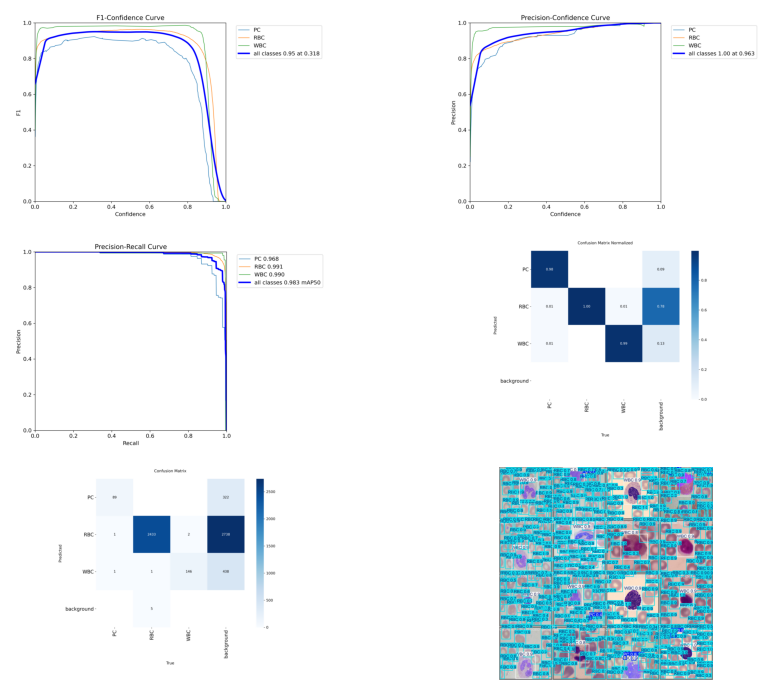

In [24]:
import os
from skimage import io
import matplotlib.pyplot as plt
import time
%matplotlib inline

fig, axes = plt.subplots(3, 2, figsize=(10, 7))
ax = axes.ravel()
res_path = results.save_dir  # folder where model.val saved its plots
for i, res_plot in enumerate(['BoxF1_curve.png', 'BoxP_curve.png', 'BoxPR_curve.png', 'confusion_matrix_normalized.png', 'confusion_matrix.png', 'val_batch0_pred.jpg']):
    res = io.imread(f"{res_path}/{res_plot}")
    ax[i].imshow(res)
    ax[i].axis('off')
plt.tight_layout()
plt.show()

In [25]:
# do the same manually for some curves and create FPPI as an addition
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve, average_precision_score

def run_inference_and_collect(model_path, image_folder, label_folder, iou_thr=0.5):
    model = YOLO(model_path)
    rows = []
    n_gt = {}  # GT boxes per class, the recall denominator

    for r in model.predict(image_folder, stream=True, imgsz=640, conf=0.001):
        img_name = os.path.basename(r.path)
        stem = os.path.splitext(img_name)[0]
        lab = os.path.join(label_folder, stem + ".txt")
        if not os.path.exists(lab):
            continue

        img_width, img_height = r.orig_shape[1], r.orig_shape[0]

        # load GT YOLO → absolute xyxy
        gt = np.loadtxt(lab).reshape(-1, 5)
        gt_abs = []
        for c, xc, yc, w, h in gt:
            x1 = (xc - w / 2) * img_width
            y1 = (yc - h / 2) * img_height
            x2 = (xc + w / 2) * img_width
            y2 = (yc + h / 2) * img_height
            gt_abs.append([c, x1, y1, x2, y2])
        gt_abs = np.array(gt_abs)
        for c in gt[:, 0]:
            n_gt[int(c)] = n_gt.get(int(c), 0) + 1

        if r.boxes is None:
            continue

        det = r.boxes
        det_xyxy = det.xyxy.cpu().numpy()
        det_conf = det.conf.cpu().numpy()
        det_cls = det.cls.cpu().numpy()

        used = np.zeros(len(gt_abs), dtype=bool)

        for i in range(len(det_xyxy)):
            dx1, dy1, dx2, dy2 = det_xyxy[i]
            dconf = det_conf[i]
            dcls = det_cls[i]

            ious = []
            for j, g in enumerate(gt_abs):
                gx1, gy1, gx2, gy2 = g[1], g[2], g[3], g[4]
                ix1 = max(dx1, gx1)
                iy1 = max(dy1, gy1)
                ix2 = min(dx2, gx2)
                iy2 = min(dy2, gy2)
                inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
                ua = (dx2 - dx1) * (dy2 - dy1) + (gx2 - gx1) * (gy2 - gy1) - inter
                iou = inter / ua if ua > 0 and g[0] == dcls else 0  # only same-class matches
                ious.append(iou)

            if len(ious) == 0:
                rows.append([dconf, 0, 1, int(dcls)])
                continue

            jmax = int(np.argmax(ious))
            best = ious[jmax]

            # single-match policy
            if best >= iou_thr and not used[jmax]:
                used[jmax] = True
                rows.append([dconf, 1, 0, int(dcls)])
            else:
                rows.append([dconf, 0, 1, int(dcls)])

    df = pd.DataFrame(rows, columns=["conf", "tp", "fp", "cls"])
    return df, n_gt


def plot_pr_curve(df, n_gt):
    # sort by confidence descending
    df = df.sort_values("conf", ascending=False)
    tp_cum = df["tp"].cumsum().values
    fp_cum = df["fp"].cumsum().values

    precision = tp_cum / np.maximum(tp_cum + fp_cum, 1e-9)
    recall = tp_cum / sum(n_gt.values())

    plt.figure()
    plt.plot(recall, precision)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("PR Curve")
    plt.grid(True)
    plt.show()


def plot_fppi_tpr(df, num_images, n_gt):
    df = df.sort_values("conf", ascending=False)
    tp_cum = df["tp"].cumsum().values
    fp_cum = df["fp"].cumsum().values

    tpr = tp_cum / sum(n_gt.values())
    fppi = fp_cum / num_images

    plt.figure()
    plt.plot(fppi, tpr)
    plt.xlabel("FPPI")
    plt.ylabel("TPR")
    plt.title("FPPI–TPR")
    plt.grid(True)
    plt.show()


def compute_map_table(iou_list):
    # iou_list: [(iou, df, n_gt)], each df matched at its own IoU threshold
    records = []
    for iou, dfi, n_gt in iou_list:
        aps = []
        for c, n in n_gt.items():
            d = dfi[dfi["cls"] == c].sort_values("conf", ascending=False)
            tp_cum = d["tp"].cumsum().values
            fp_cum = d["fp"].cumsum().values
            precision = tp_cum / np.maximum(tp_cum + fp_cum, 1e-9)
            recall = tp_cum / n

            ap = 0
            for r in np.linspace(0, 1, 11):
                p = precision[recall >= r].max() if np.any(recall >= r) else 0
                ap += p
            aps.append(ap / 11)

        records.append([iou, np.mean(aps)])

    return pd.DataFrame(records, columns=["IoU", "mAP"])


In [26]:
model_path = "runs/detect/from_scratch_50e_v1/weights/best.pt"  # change if needed
image_folder = f"{root_path}/test/images"  # change if needed
label_folder = f"{root_path}/test/labels"  # change if needed
results, n_gt = run_inference_and_collect(model_path, image_folder, label_folder, iou_thr=0.5)
results.head()


image 1/144 /content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11/test/images/01e4af27-0d62-557e-b967-cd665b590d45_jpg.rf.a29b17fedb7f142ab8a107cd6d4f0bbd.jpg: 640x640 1 PC, 54 RBCs, 1 WBC, 9.5ms
image 2/144 /content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11/test/images/02db46d5-f0f3-511c-b2cc-e907946e88e2_jpg.rf.5ebfbef49efe96859b237d59acd2a0df.jpg: 640x640 3 PCs, 66 RBCs, 1 WBC, 10.4ms
image 3/144 /content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11/test/images/035e0876-5358-5118-a956-116f8af710e4_jpg.rf.c6270d89a7f0ec150cfac4376bfa575d.jpg: 640x640 5 PCs, 69 RBCs, 1 WBC, 9.4ms
image 4/144 /content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11/test/images/0434941c-bce6-5060-b800-748937b7ea97_jpg.rf.b639ef3b6d52f6105852a31ca5607524.jpg: 640x640 2 PCs, 56 RBCs, 1 WBC, 9.4ms
image 5/144 /content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11/test/images/044

,conf,tp,fp,cls
0,0.946613,1,0,1
1,0.945516,1,0,1
2,0.941955,1,0,1
3,0.936286,1,0,1
4,0.935322,1,0,1


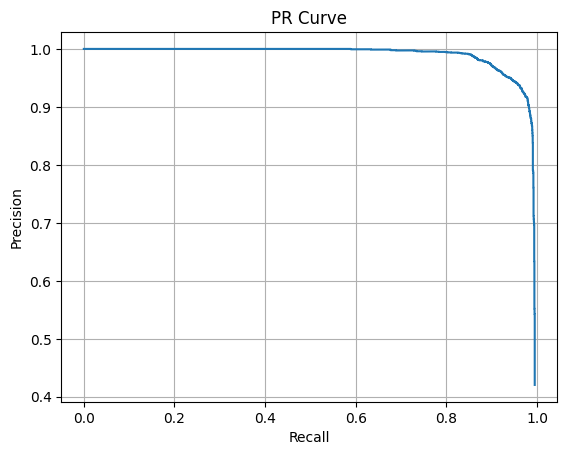

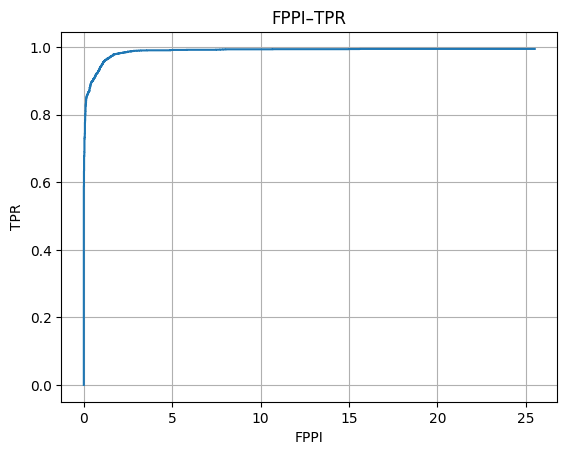


image 1/144 /content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11/test/images/01e4af27-0d62-557e-b967-cd665b590d45_jpg.rf.a29b17fedb7f142ab8a107cd6d4f0bbd.jpg: 640x640 1 PC, 54 RBCs, 1 WBC, 10.4ms
image 2/144 /content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11/test/images/02db46d5-f0f3-511c-b2cc-e907946e88e2_jpg.rf.5ebfbef49efe96859b237d59acd2a0df.jpg: 640x640 3 PCs, 66 RBCs, 1 WBC, 10.3ms
image 3/144 /content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11/test/images/035e0876-5358-5118-a956-116f8af710e4_jpg.rf.c6270d89a7f0ec150cfac4376bfa575d.jpg: 640x640 5 PCs, 69 RBCs, 1 WBC, 10.4ms
image 4/144 /content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11/test/images/0434941c-bce6-5060-b800-748937b7ea97_jpg.rf.b639ef3b6d52f6105852a31ca5607524.jpg: 640x640 2 PCs, 56 RBCs, 1 WBC, 10.6ms
image 5/144 /content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO/blood_cell.v1i.yolov11/test/images/

In [27]:
plot_pr_curve(results, n_gt)
plot_fppi_tpr(results, num_images=len(os.listdir(image_folder)), n_gt=n_gt)
ious = np.arange(0.5, 1.0, 0.05)
mAP = compute_map_table([(iou, *run_inference_and_collect(model_path, image_folder, label_folder, iou_thr=iou)) for iou in ious])
print(mAP)
print("mAP@0.5:", mAP["mAP"].iloc[0], "| mAP@0.5:0.95:", mAP["mAP"].mean())